## Outlier Detection

I examined unusual earnings histories using different outlier detection methods with the goal of understanding which observations they flagged and how much their results agreed. I also tested whether removing the observations flagged by Isolation Forest improved classification performance. I used the pre-2024 development data for these experiments and kept the reserved 2024 holdout untouched.

In [1]:
import json

from pathlib import Path

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "pyproject.toml").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent

OUTLIER_RESULTS_DIR = PROJECT_ROOT / "results" / "outliers"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"

isolation_results_path = OUTLIER_RESULTS_DIR / "isolation_forest_initial.json"

comparison_results_path = OUTLIER_RESULTS_DIR / "three_detector_comparison.json"

with isolation_results_path.open(encoding="utf-8") as file:
    isolation_results = json.load(file)

with comparison_results_path.open(encoding="utf-8") as file:
    comparison_results = json.load(file)

print(
    "Full-development Isolation Forest observations: "
    f"{isolation_results['samples']:,}"
)

print(
    "Three-detector comparison observations: " f"{comparison_results['sample_count']:,}"
)

Full-development Isolation Forest observations: 82,353
Three-detector comparison observations: 4,000


### Isolation Forest

I used Isolation Forest first to examine unusual earnings histories across the development dataset. This analysis included all 82,353 observations dated before 2024. I excluded the 2024 holdout.

I fitted the model using 200 trees and the 39 transformed features. I set the contamination parameter to 0.05 which determines the cutoff used to flag approximately 5% of the observations.

In [2]:
import pandas as pd

from IPython.display import display

isolation_summary = pd.DataFrame(
    {
        "Metric": [
            "Observations",
            "Transformed features",
            "Trees",
            "Contamination setting",
            "Flagged observations",
            "Unflagged observations",
            "Percentage flagged",
        ],
        
        "Value": [
            f"{isolation_results['samples']:,}",
            isolation_results["feature_count"],
            isolation_results["tree_count"],
            isolation_results["contamination"],
            f"{isolation_results['outlier_count']:,}",
            f"{isolation_results['inlier_count']:,}",
            f"{isolation_results['outlier_fraction']:.2%}",
        ],
    }
)

display(isolation_summary)

,Metric,Value
0,Observations,"82,353"
1,Transformed features,39
2,Trees,200
3,Contamination setting,0.05
4,Flagged observations,"4,118"
5,Unflagged observations,"78,235"
6,Percentage flagged,5.00%


#### Initial Findings

Isolation Forest flagged 4,118 observations which meant that 78,235 were left unflagged. The flagged proportion was approximately 5%, consistent with the contamination setting I chose.

I kept the flagged observations for further examination because unusual earnings histories may still contain valid financial information and the detector alone does not establish whether a record is incorrect.

#### Isolation Forest Diagnostics

I plotted the Isolation Forest anomaly scores across all 82,353 development observations to examine how the flagged observations differ from the rest of the data.

I also used PCA to visualize a sample of 4,000 observations in two dimensions. PCA was used for visualization and Isolation Forest was fitted using the original 39 transformed features.

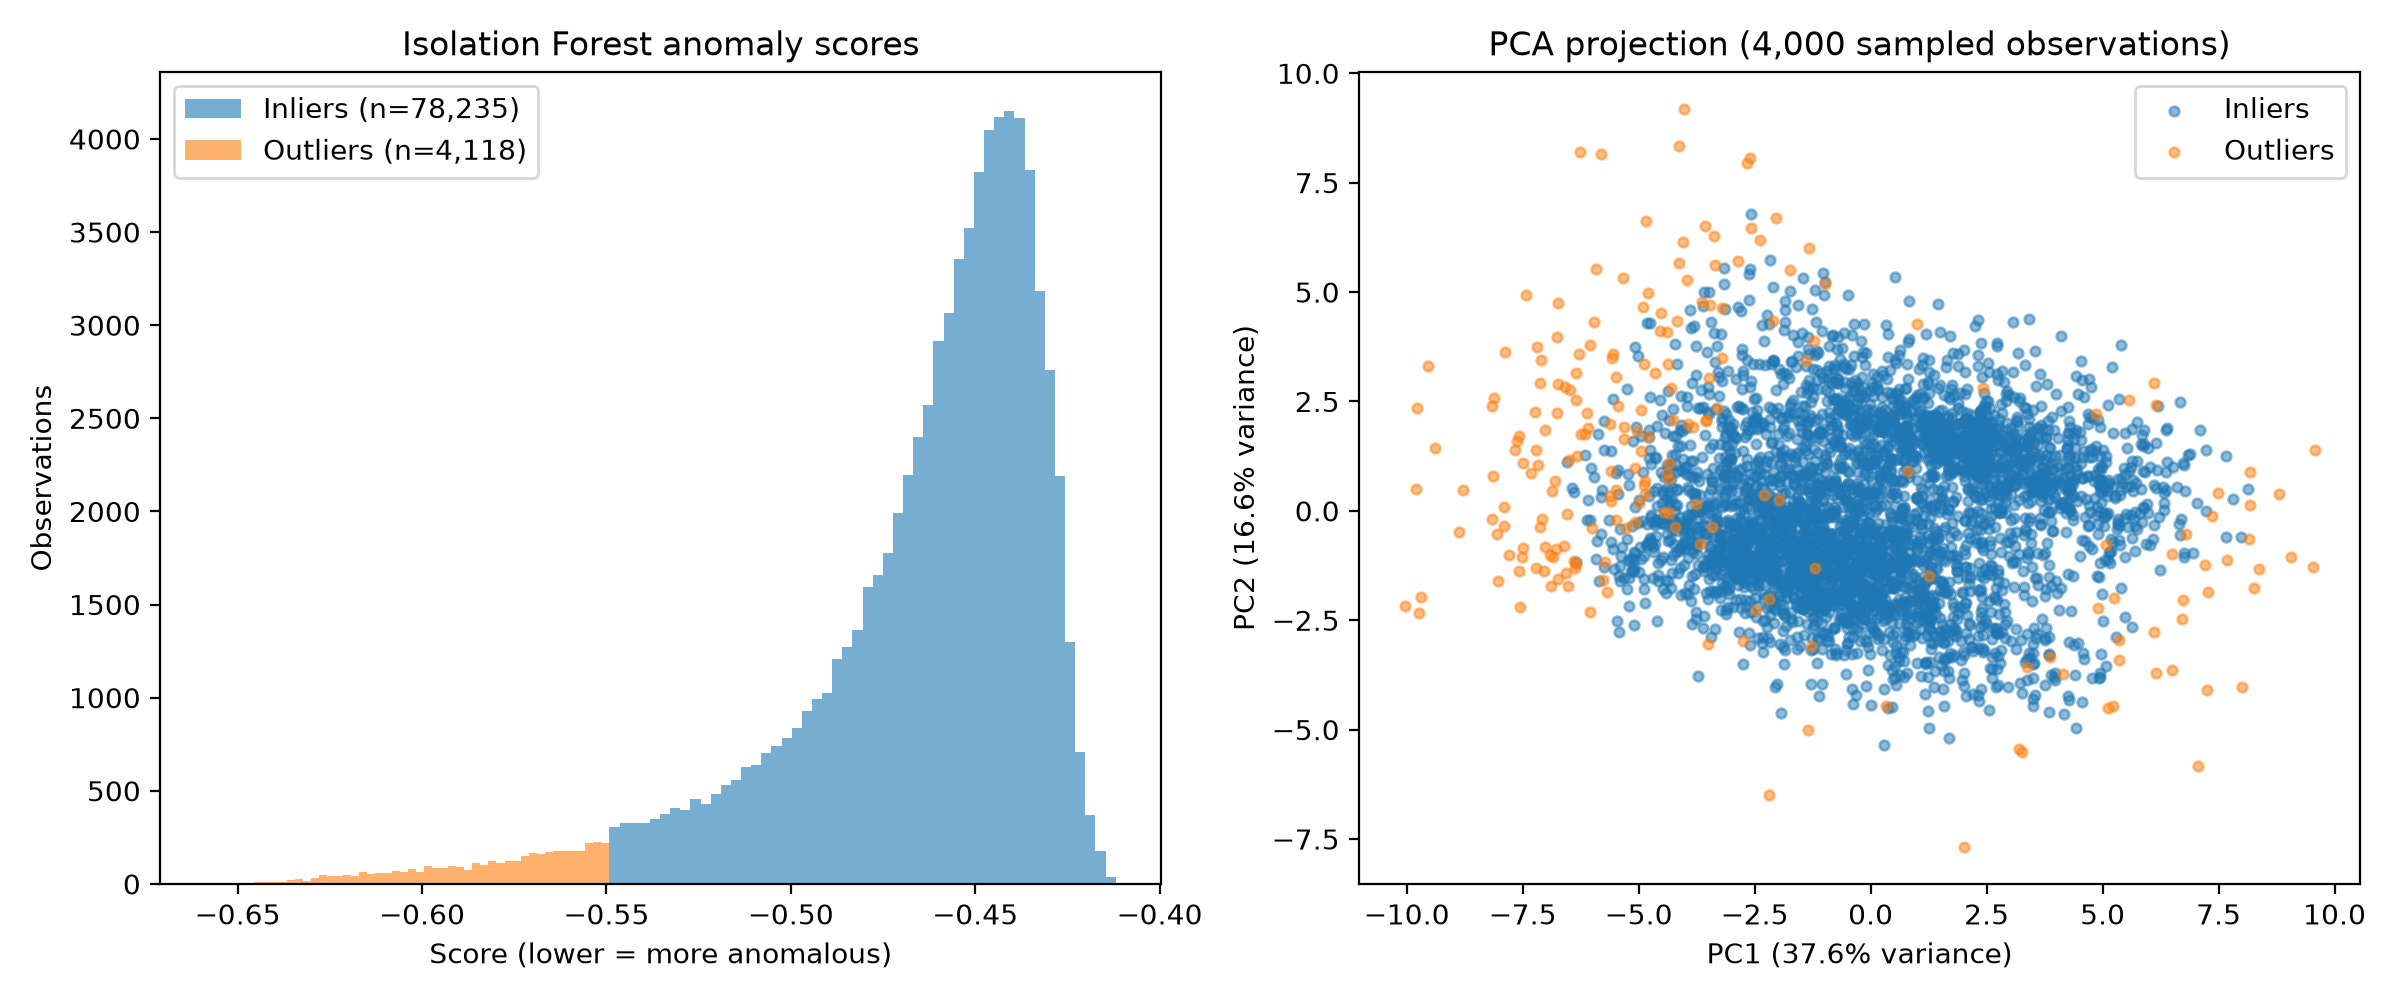

In [3]:
from IPython.display import Image

diagnostics_path = FIGURES_DIR / "isolation_forest_diagnostics.png"

display(Image(filename=str(diagnostics_path)))

#### Interpretation

The anomaly score distribution shows that the flagged observations have lower scores than the unflagged observations. In the PCA projection I observed that many flagged observations lie further from the main concentration of data, although some overlap with the unflagged observations.

The first two principal components explain 54.2% of the variance so the projection does not capture all of the information used by Isolation Forest. The plots suggest that the detector is identifying unusual feature combinations but they do not establish whether these observations are invalid.

#### Feature Profiles

I compared the historical earnings features of the flagged and unflagged observations to better understand their differences. I examined the median values and median absolute values to account for the influence of extreme earnings results.

In [4]:
profile_path = OUTLIER_RESULTS_DIR / "isolation_forest_profile.csv"

profile = pd.read_csv(profile_path)

profile_comparison = profile.set_index("feature")

display(profile_comparison.round(3))

,inlier_median,outlier_median,inlier_median_absolute,outlier_median_absolute,inlier_missing_fraction,outlier_missing_fraction
feature,,,,,,
actual_eps_lag1,0.320,-4.400,0.480,7.335,0.0,0.0
estimate_eps_lag1,0.290,-3.000,0.440,5.700,0.0,0.0
surprise_mean4,0.025,-0.125,0.055,2.085,0.0,0.0
surprise_std4,0.069,2.951,0.069,2.951,0.0,0.0
beat_rate4,0.750,0.500,0.750,0.500,0.0,0.0
beat_streak4,1.000,0.000,1.000,0.000,0.0,0.0
eps_change1_2,0.010,0.560,0.110,3.100,0.0,0.0
eps_trend4,0.009,0.404,0.054,1.736,0.0,0.0


#### Interpretation

The flagged observations showed noticeably greater variation in their historical earnings. Their median `surprise_std4` was 2.951, compared with 0.069 for unflagged observations. The median absolute EPS change between the two most recent events was also much larger (3.100 compared with 0.110).

I also found that flagged observations had a lower median historical beat rate (0.50 compared with 0.75) and a shorter median beat streak. Their median previous actual EPS was -4.400, compared with 0.320 for unflagged observations.

These differences suggest that Isolation Forest is identifying earnings histories with larger fluctuations and more negative recent earnings. I did not consider these observations invalid based on these results alone, since substantial earnings changes may reflect genuine financial events.

### Comparison of Outlier Detection Methods

I compared Isolation Forest with Local Outlier Factor (LOF) and One-Class SVM to examine whether different methods identify similar observations as outliers.

I used the same sample of 4,000 development observations for each method. I compared the proportion of observations flagged and the agreement between the detectors.

In [5]:
detector_counts = comparison_results["detector_outliers"]
agreement_counts = comparison_results["agreement_counts"]
sample_count = comparison_results["sample_count"]

detector_table = pd.DataFrame(
    {
        "Detector": [
            "Isolation Forest",
            "Local Outlier Factor",
            "One-Class SVM",
        ],
        
        "Flagged": [
            detector_counts["isolation_forest"],
            detector_counts["local_outlier_factor"],
            detector_counts["one_class_svm"],
        ],
    }
)

detector_table["Flagged (%)"] = (100 * detector_table["Flagged"] / sample_count).round(
    2
)

display(detector_table)

agreement_table = pd.DataFrame(
    {
        "Agreement": [
            "Not flagged",
            "Flagged by one",
            "Flagged by two",
            "Flagged by all three",
        ],
        
        "Observations": [
            agreement_counts["none"],
            agreement_counts["exactly_one"],
            agreement_counts["exactly_two"],
            agreement_counts["all_three"],
        ],
    }
)

display(agreement_table)

,Detector,Flagged,Flagged (%)
0,Isolation Forest,200,5.00
1,Local Outlier Factor,200,5.00
2,One-Class SVM,195,4.88


,Agreement,Observations
0,Not flagged,3678
1,Flagged by one,135
2,Flagged by two,101
3,Flagged by all three,86


#### Detector Agreement

All three methods flagged approximately 5% of the sampled observations, but the methods did differ in terms of which observations they identified.

Of the 4,000 observations, 322 were flagged by at least one detector and only 86 were flagged by all three. Another 135 observations were flagged by just one method.

I found that the detectors agreed on some unusual earnings histories but their results were far from identical, suggesting that the methods respond differently to the patterns in the data.

In [6]:
pairwise_agreement = comparison_results["pairwise_agreement"]

detector_pairs = {
    "Isolation Forest vs. LOF": "isolation_forest_vs_local_outlier_factor",
    "Isolation Forest vs. One-Class SVM": "isolation_forest_vs_one_class_svm",
    "LOF vs. One-Class SVM": "local_outlier_factor_vs_one_class_svm",
}

comparison_rows = []

for name, key in detector_pairs.items():
    results = pairwise_agreement[key]

    comparison_rows.append(
        {
            "Detector Pair": name,
            "Shared Outliers": results["intersection"],
            "Total Unique Outliers": results["union"],
            "Jaccard Similarity": results["jaccard_similarity"],
        }
    )

jaccard_table = pd.DataFrame(comparison_rows)

display(jaccard_table.round(3))

,Detector Pair,Shared Outliers,Total Unique Outliers,Jaccard Similarity
0,Isolation Forest vs. LOF,89,311,0.286
1,Isolation Forest vs. One-Class SVM,140,255,0.549
2,LOF vs. One-Class SVM,130,265,0.491


#### Pairwise Agreement

I used Jaccard similarity to compare the observations flagged by each pair of detectors. It measures the number of observations flagged by both methods divided by the total number flagged by either method. Higher values indicate greater overlap.

Isolation Forest and One-Class SVM had the highest agreement with a Jaccard similarity of 0.549 and 140 shared outliers. Isolation Forest and LOF had the lowest agreement at 0.286, sharing only 89 observations.

Despite the detectors flagging similar numbers of observations they did not consistently identify the same earnings histories, suggesting that the choice of detection method has a considerable effect on which observations are treated as unusual.

### Effect of Outlier Removal on Classification

I tested whether removing the observations flagged by Isolation Forest would improve XGBoost's predictive performance.

For each chronological validation fold from 2020 to 2023 I fitted Isolation Forest using only the training observations and removed approximately 5% of them. I then trained XGBoost on the filtered data and compared its performance against the same model trained without removing outliers.

Both models were evaluated on the same unfiltered validation observations. The reserved 2024 holdout was excluded from this experiment.

In [7]:
filter_impact_path = OUTLIER_RESULTS_DIR / "xgboost_filter_impact.json"

with filter_impact_path.open(encoding="utf-8") as file:
    filter_impact_results = json.load(file)


fold_rows = []

for fold in filter_impact_results["folds"]:
    fold_rows.append(
        {
            "Year": fold["validation_year"],
            "Removed": fold["removed_training_samples"],
            "Unfiltered F1": fold["baseline"]["macro_f1"],
            "Filtered F1": fold["filtered"]["macro_f1"],
            "Difference": fold["macro_f1_difference"],
        }
    )

fold_table = pd.DataFrame(fold_rows)

display(fold_table.round(4))


mean_performance = filter_impact_results["mean_performance"]

metric_names = {
    "accuracy": "Accuracy",
    "macro_f1": "Macro F1",
    "roc_auc": "ROC-AUC",
}

mean_rows = []

for metric, name in metric_names.items():
    mean_rows.append(
        {
            "Metric": name,
            "Unfiltered": mean_performance["baseline"][metric],
            "Filtered": mean_performance["filtered"][metric],
            "Difference": mean_performance["difference_filtered_minus_baseline"][
                metric
            ],
        }
    )

mean_table = pd.DataFrame(mean_rows)

display(mean_table.round(4))

,Year,Removed,Unfiltered F1,Filtered F1,Difference
0,2020,1230,0.6070,0.6065,-0.0004
1,2021,1902,0.6582,0.6528,-0.0054
2,2022,2594,0.6210,0.6218,0.0008
3,2023,3335,0.6146,0.6151,0.0005


,Metric,Unfiltered,Filtered,Difference
0,Accuracy,0.6689,0.6669,-0.0020
1,Macro F1,0.6252,0.6241,-0.0011
2,ROC-AUC,0.6946,0.6930,-0.0015


#### Interpretation

Removing the flagged observations did not consistently improve XGBoost's performance. Macro F1 decreased in 2020 and 2021 with the largest decrease occurring in 2021. Filtering produced small improvements in 2022 and 2023.

Across the four validation years, mean macro F1 decreased from 0.6252 to 0.6241. Mean accuracy and ROC-AUC also decreased slightly.

### Conclusion

I examined unusual earnings histories using Isolation Forest and compared its results with Local Outlier Factor and One-Class SVM. Although the methods flagged similar proportions of observations, they differed considerably in which records they identified. The feature profiles showed that observations flagged by Isolation Forest tended to have much larger historical earnings fluctuations.

I also tested whether removing these observations improved XGBoost's performance. Filtering produced a small decrease in average macro F1, from 0.6252 to 0.6241, across the four validation years.

I decided to retain the flagged observations for the remaining classification experiments. Their unusual values may represent genuine financial events, and I found no evidence that removing them improved predictive performance under the tested approach.